# 03 · ONI rezagado en el modelo B y corrección del back-transform (Gate 3, parte 1)

Dos preguntas: (1) ¿mejora el modelo B (`fourier_arima012`: Fourier K=2 + ARIMA(0,1,2) sobre log1p) fuera de muestra si se añade el ONI rezagado? (2) ¿reduce el sesgo negativo en los picos una corrección del back-transform (`expm1` del pronóstico en log es una *mediana*, no una media)?

**Sin fuga.** El ONI de un mes se publica ~1 mes después de terminar (≈ 8-9 semanas desde una semana de ese mes). Para el origen *t* y el objetivo *t+h* (h ≤ 12) se usa ONI(t+h−lag), que debe estar publicado en *t*: lag ≥ 12+9 = 21 semanas. Candidatos: 21, 26, 34, 43. El código enmascara todo ONI posterior a *t*−9 semanas y hay tests que lo verifican (`tests/test_oni.py`).

## 1. Elección del lag (solo 2012–2020)

Todos los modelos (B y B+ONI en cada lag) se ajustan sobre **las mismas filas**: hasta 2020-12-28, descartando las primeras 43 semanas (donde el ONI con lag 43 no existe) para todos, B incluido; así AIC/BIC y el test de razón de verosimilitudes son comparables. Regla fijada antes de mirar: gana el menor AIC. No se usó el backtest 2021–2025.

In [1]:
import pandas as pd
pd.set_option('display.width', 200)
sel = pd.read_csv('../results/oni_lag_selection.csv')
sel[['model','lag_weeks','n_rows','aic','bic','d_aic_vs_B','d_bic_vs_B','beta_oni','z_oni','lr_stat','lr_pvalue']].round(3)

,model,lag_weeks,n_rows,aic,bic,d_aic_vs_B,d_bic_vs_B,beta_oni,z_oni,lr_stat,lr_pvalue
0,B,NaN,425,919.166,948.176,0.000,0.000,NaN,NaN,NaN,NaN
1,B+ONI,21.0,425,916.020,949.173,-3.146,0.998,0.236,2.666,5.146,0.023
2,B+ONI,26.0,425,915.387,948.541,-3.779,0.365,0.254,3.089,5.779,0.016
3,B+ONI,34.0,425,914.964,948.118,-4.202,-0.058,0.265,3.124,6.202,0.013
4,B+ONI,43.0,425,916.926,950.080,-2.240,1.904,0.223,2.354,4.240,0.039


Todos los lags bajan el AIC respecto de B (−2.2 a −4.2) y el coeficiente es positivo (más ONI, es decir El Niño, más focos) y con z entre 2.4 y 3.1. **Gana lag = 34 semanas** (AIC −4.2; también el único con BIC menor que B, y por poco: −0.06). El LR vs B da p = 0.013 sin corregir; con Bonferroni por los 4 lags probados son ≈ 0.05: evidencia en muestra **marginal**, no contundente.

## 2. Backtest y back-transform

Mismo arnés que Gate 2 (63 orígenes, 2021-01-04 → 2025-10-06, h=1..12, reajuste en cada origen, órdenes fijos). El modelo B+ONI se entrena sin las primeras `lag` semanas (el ONI aún no existe) mientras B usa todo: diferencia de 34 semanas sobre ~500, despreciable. Re-ejecutar B con el código nuevo reproduce exactamente su `y_pred` de Gate 2.

Back-transforms sobre la media log *f*: **mediana** `expm1(f)`; **Duan** `exp(f)·mean(exp(e)) − 1`; **sigma2** `expm1(f + σ²/2)`; *e* y σ² son los residuos a un paso dentro de muestra *en cada origen*. **Primario: Duan**, elegido a priori por no suponer normalidad. Ambos usan el mismo factor para todos los h (residuos a un paso), lo que subcorrige a h largo.

In [2]:
from fires import compare_oni as co
from fires.backtest import RESULTS
fcs = co.load()
for m in (co.B, co.BONI):
    log = pd.read_csv(RESULTS / 'forecasts' / f'{m}_fitlog.csv')
    print(m, 'no convergidos:', int((~log['converged']).sum()), 'de', len(log), '| excepciones:', int(log['error'].notna().sum()))
t = co.comparison(fcs)
t.to_csv(RESULTS / 'metrics' / 'gate3_oni_comparison.csv', index=False)
s = t[t.h.isin([1, 4, 8, 12]) & (t.model != co.NAIVE)]
print('filas por (modelo, h): n =', sorted(t.n.unique()))

fourier_arima012 no convergidos: 0 de 63 | excepciones: 0
fourier_arima012_oni no convergidos: 0 de 63 | excepciones: 0


filas por (modelo, h): n = [np.int64(49), np.int64(50), np.int64(60), np.int64(61), np.int64(62), np.int64(63)]


### MAE relativo a B (mismo back-transform); < 1 = B+ONI mejora

In [3]:
s[s.model == co.BONI].pivot_table(index=['eval_set','h'], columns='backtransform', values='mae_ratio_vs_B').round(3)

backtransform   duan  median  sigma2
eval_set  h                         
all       1    0.943   0.952   0.945
          4    0.913   0.966   0.915
          8    0.933   0.949   0.934
          12   0.905   0.933   0.905
excl_2024 1    0.996   0.996   0.996
          4    0.939   0.972   0.941
          8    0.933   0.946   0.936
          12   0.913   0.943   0.913

### MAE relativo a seasonal naive

In [4]:
s.pivot_table(index=['eval_set','h'], columns=['model','backtransform'], values='mae_ratio_vs_naive').round(3)

model         fourier_arima012               fourier_arima012_oni              
backtransform             duan median sigma2                 duan median sigma2
eval_set  h                                                                    
all       1              0.511  0.472  0.512                0.482  0.450  0.484
          4              0.566  0.518  0.565                0.516  0.500  0.517
          8              0.595  0.586  0.593                0.555  0.557  0.554
          12             0.621  0.612  0.620                0.562  0.571  0.561
excl_2024 1              0.542  0.542  0.544                0.539  0.539  0.542
          4              0.597  0.510  0.597                0.560  0.496  0.561
          8              0.639  0.552  0.637                0.596  0.522  0.596
          12             0.652  0.568  0.651                0.595  0.536  0.594

### Sesgo medio (pred − real, hotspots/semana)

Con la mediana B subestima (−1.1k a −1.7k con todos los targets); Duan y sigma2 llevan el sesgo cerca de cero. B+ONI con mediana subestima aún más (−1.5k a −2.0k); corregido queda cerca de cero y, en casi todos los h, más cerca que B corregido.

In [5]:
s.pivot_table(index=['eval_set','h'], columns=['model','backtransform'], values='bias').round(0)

model         fourier_arima012                fourier_arima012_oni                
backtransform             duan  median sigma2                 duan  median  sigma2
eval_set  h                                                                       
all       1              257.0 -1432.0  276.0               -176.0 -1722.0  -132.0
          4              622.0 -1089.0  640.0                 39.0 -1498.0    83.0
          8              387.0 -1275.0  406.0               -210.0 -1695.0  -165.0
          12             -58.0 -1650.0  -37.0               -607.0 -2035.0  -561.0
excl_2024 1             -821.0 -1991.0 -792.0              -1053.0 -2138.0 -1007.0
          4              615.0  -628.0  643.0                256.0  -873.0   302.0
          8              861.0  -435.0  887.0                344.0  -803.0   391.0
          12             842.0  -473.0  867.0                184.0  -951.0   232.0

### MAE en números absolutos

La corrección **cuesta MAE**: el MAE se minimiza con la mediana, no con la media. Con todos los targets sube 2-10 %, y sin 2024 sube 0-17 % (h=4: 2997 → 3506 para B).

In [6]:
s.pivot_table(index=['eval_set','h'], columns=['model','backtransform'], values='mae').round(0)

model         fourier_arima012                 fourier_arima012_oni                
backtransform             duan  median  sigma2                 duan  median  sigma2
eval_set  h                                                                        
all       1             4069.0  3758.0  4077.0               3836.0  3579.0  3852.0
          4             4301.0  3935.0  4298.0               3926.0  3803.0  3931.0
          8             4518.0  4456.0  4508.0               4216.0  4229.0  4213.0
          12            4779.0  4710.0  4774.0               4327.0  4396.0  4318.0
excl_2024 1             3495.0  3495.0  3510.0               3481.0  3480.0  3496.0
          4             3506.0  2997.0  3506.0               3291.0  2913.0  3298.0
          8             3748.0  3237.0  3739.0               3496.0  3063.0  3498.0
          12            3879.0  3381.0  3874.0               3541.0  3190.0  3538.0

### ¿Se reduce la subestimación en los picos?

Sesgo restringido a los objetivos de agosto a octubre (temporada pico), h=4, todos los targets comunes (solo 15 semanas, de 3-4 temporadas: indicativo). La corrección **sobrecorrige** en el pico: el factor de Duan es constante (~1.26) y los residuos log son más dispersos fuera de temporada, así que en agosto-octubre, donde los conteos son altos, multiplicar por 1.26 pasa de −1.9k (mediana) a +3.2k en B. B+ONI corregido es el que queda más cerca de cero (+1.2k).

In [7]:
import numpy as np
from fires.metrics import common_targets
common = common_targets({m: fcs[m] for m in (co.NAIVE, co.B, co.BONI)})
rows = []
for m in (co.B, co.BONI):
    d = common[m]
    d = d[(d.h == 4) & d.target_week.dt.month.isin([8, 9, 10])]
    for bt, col in co.BACKTRANSFORMS.items():
        rows.append({'model': m, 'backtransform': bt, 'bias_aug_oct': (d[col] - d.y_true).mean(),
                     'mean_actual': d.y_true.mean(), 'n': len(d)})
pd.DataFrame(rows).round(0)

,model,backtransform,bias_aug_oct,mean_actual,n
0,fourier_arima012,median,-1950.0,21202.0,15
1,fourier_arima012,duan,3168.0,21202.0,15
2,fourier_arima012,sigma2,3219.0,21202.0,15
3,fourier_arima012_oni,median,-3349.0,21202.0,15
4,fourier_arima012_oni,duan,1202.0,21202.0,15
5,fourier_arima012_oni,sigma2,1329.0,21202.0,15


## 3. Figura: MAE por horizonte

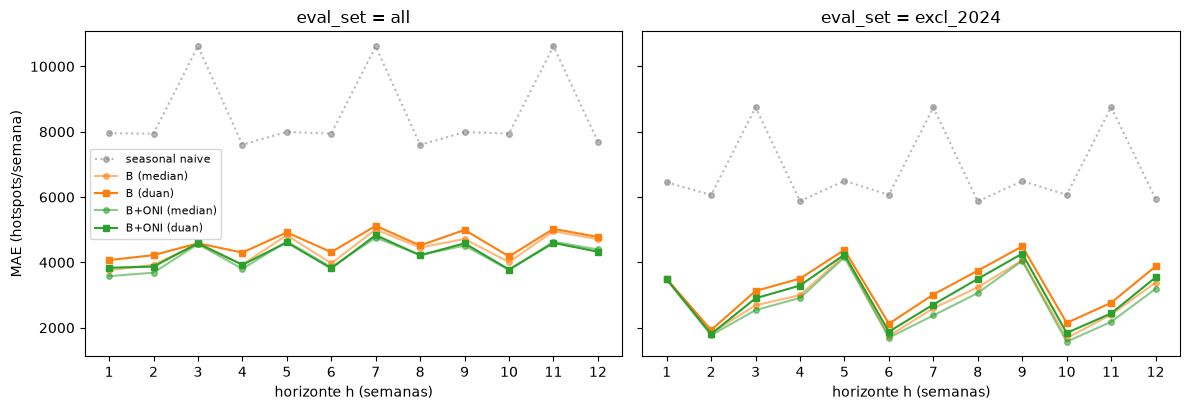

In [8]:
import matplotlib.pyplot as plt
co.plot_mae(t)
plt.show()

## 4. Diebold–Mariano: B+ONI vs B (error absoluto, un valor por origen)

d = |e_B| − |e_B+ONI| por origen; d > 0 favorece a B+ONI. Varianza HAC con ancho q = ⌊(h−1)/4⌋ orígenes (los orígenes están a 4 semanas), corrección de Harvey–Leybourne–Newbold y t de Student. **Pocos orígenes independientes:** son 60-63 por h, pero los errores de h=12 de orígenes vecinos comparten semanas, y los 5 años cubren apenas 2-3 episodios ENSO (La Niña 2021-22, El Niño 2023-24), de modo que el tamaño efectivo de muestra es mucho menor que n. Un p-valor aquí es orientativo.

In [9]:
dm = co.dm_table(fcs)
dm.to_csv(RESULTS / 'metrics' / 'gate3_oni_dm.csv', index=False)
dm.round(4)

,backtransform,eval_set,h,n,mean_diff,dm_stat,p_value,share_oni_better
0,median,all,4,63,132.4777,1.1933,0.2373,0.6349
1,median,all,12,62,313.5709,1.7466,0.0857,0.5806
2,median,excl_2024,4,50,83.6465,0.9208,0.3617,0.5800
3,median,excl_2024,12,49,191.1621,0.9827,0.3307,0.5102
4,duan,all,4,63,374.8746,1.6565,0.1027,0.5556
5,duan,all,12,62,452.1783,1.8965,0.0626,0.5806
6,duan,excl_2024,4,50,215.3263,2.1342,0.0379,0.5400
7,duan,excl_2024,12,49,337.7725,1.2617,0.2132,0.5306
8,sigma2,all,4,63,366.9522,1.6599,0.1020,0.5714
9,sigma2,all,12,62,455.6787,1.9536,0.0553,0.6129


## Conclusión

**¿Ayuda el ONI rezagado?** Algo, pero con evidencia débil. Lag elegido 34 semanas (solo con 2012-2020; LR p=0.013, ≈0.05 con Bonferroni). Fuera de muestra, B+ONI baja el MAE un 3-7 % respecto de B con la mediana (todos los targets: ratio 0.95/0.97/0.95/0.93 en h=1/4/8/12; sin 2024: 1.00/0.97/0.95/0.94), y la mejora crece con el horizonte, que es donde cabe esperarla. Con el back-transform corregido la mejora es algo mayor (ratio 0.91-0.94 en h≥4). Pero Diebold-Mariano no lo respalda con holgura: con la mediana p = 0.09-0.36; con Duan solo h=4 sin 2024 llega a p=0.04 y el resto 0.06-0.21. Con ~3 episodios ENSO en la muestra el p-valor es optimista incluso cuando sale bajo. Lectura honesta: una mejora pequeña y consistente en signo, no demostrada.

**¿Reduce la corrección el sesgo?** Sí en el promedio, no en los picos, y cuesta MAE. Duan y sigma2 son casi idénticos; con ellos el sesgo medio de B pasa de −1.1k/−1.7k a ≈ 0 (rango −0.06k a +0.9k), pero el MAE sube 2-10 % (todos) y hasta 17 % (sin 2024, h=4) porque el MAE premia la mediana. En agosto-octubre la corrección constante sobrecorrige (B: −1.9k → +3.2k). Conclusión práctica: mediana si el criterio es MAE; media corregida si interesa el total esperado de focos; para los picos haría falta una corrección que dependa del nivel o la estación (no hecha aquí).